# Polarised datings: nDFU on the expert answers

This notebook goes with `expert_disagreement.ipynb`. It asks on which papyri the experts do not just spread around one date but split into separate groups (poles).

We measure this with the **normalised Distance From Unimodality (nDFU)** of Pavlopoulos & Likas (EACL 2024; code: https://github.com/ipavlopoulos/ndfu).
nDFU takes a histogram, finds its highest bin, and looks for the largest rise between neighbouring bins on either side of it, that is, the largest departure from a single peak. It divides this rise by the height of the highest bin.
0 means one peak; 1 means two equally strong poles with an empty gap between them.

nDFU was designed for ordinal ratings (e.g. 1–5). Here an answer is a range of years, so we must choose how to bin the years, and the result depends on that choice. We therefore:
- use the **centre** of each range, one value per expert, binned in **50-year bins** (the papyri were chosen one per half-century);
- average nDFU over five positions of the bin edges, so that the result does not depend on where a bin starts;
- compare each papyrus with a **chance limit**: the 95th percentile of nDFU for 18 centres drawn from a single normal distribution with the same median and spread;
- report 25- and 100-year bins, and the pooled ranges instead of the centres, as sensitivity checks.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, GREY, GREY_L = "#2a78d6", "#eb6834", "#8a8984", "#cfcec9"
SINGLE, DOUBLE = 3.5, 7.2
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.linewidth": 0.6, "figure.dpi": 130})
os.makedirs("figures", exist_ok=True)

## The data
The same 360 answers as in the main notebook: one row per papyrus and expert. We keep the centre of each range.

In [2]:
ex = pd.read_csv("data/expert_answers.csv")
papyri = ex.groupby("papyrus")[["tm_number", "true_date"]].first().sort_values("true_date")
pids = list(papyri.index)
experts = sorted(ex.expert.unique())
y = papyri.true_date.values.astype(float)

def table(col):
    return ex.pivot(index="papyrus", columns="expert", values=col).loc[pids, experts].values.astype(float)

L, U = table("date_from"), table("date_to")
C = (L + U) / 2
nP, nE = C.shape
print(f"{nP} papyri, {nE} experts; answers span {L.min():.0f} to {U.max():.0f}")

20 papyri, 18 experts; answers span -300 to 850


## nDFU
The function below follows `ndfu.dfu` of the reference implementation line for line (normalised version).
The checks are the examples of its README. With `pip install ndfu` you can use `from ndfu import dfu` instead.

In [3]:
def dfu(hist, normalised=True):
    hist = np.asarray(hist, float)
    max_value = hist.max()
    pos_max = int(np.flatnonzero(hist == max_value)[0])
    max_diff = 0.0
    for i in range(pos_max, len(hist) - 1):          # right of the peak: any rise is a violation
        max_diff = max(max_diff, hist[i + 1] - hist[i])
    for i in range(pos_max, 0, -1):                  # left of the peak: any rise (moving left) is a violation
        max_diff = max(max_diff, hist[i - 1] - hist[i])
    return float(max_diff / max_value) if normalised else float(max_diff)

assert dfu([0.2, 0.6, 0.2]) == 0.0
assert dfu([0.5, 0.0, 0.5]) == 1.0
r = np.array([1, 1, 2, 5, 5, 5])
assert abs(dfu([(r == s).mean() for s in range(1, 6)]) - 1 / 3) < 1e-12
print("README examples reproduced")

README examples reproduced


## From answers to histograms
All histograms share one axis, from 400 BC to AD 900, which covers every answer.
- **Centres**: the 18 centres counted in bins of `width` years.
- **Pooled**: each range spread evenly over its years, then summed per bin (the pooled distribution of the main notebook, binned).

`ndfu_of` averages nDFU over five positions of the bin edges (shifts of 0, 1/5, ..., 4/5 of a bin).

In [4]:
LO, HI = -400, 900

def edges(width, offset=0):
    return np.arange(LO + offset, HI + width + 1, width)

def hist_centres(c, width, offset=0):
    h, _ = np.histogram(c, bins=edges(width, offset))
    return h / h.sum()

def hist_pooled(lo, hi, width, offset=0):
    e = edges(width, offset)
    h = np.zeros(len(e) - 1)
    for a, b in zip(lo, hi):
        h += np.clip(np.minimum(e[1:], b) - np.maximum(e[:-1], a), 0, None) / max(b - a, 1.0)
    return h / h.sum()

def offsets(width):
    return np.arange(0, width, width // 5)

def ndfu_of(p, width, kind="centres"):
    if kind == "centres":
        return np.mean([dfu(hist_centres(C[p], width, o)) for o in offsets(width)])
    return np.mean([dfu(hist_pooled(L[p], U[p], width, o)) for o in offsets(width)])

## Chance limit
With only 18 experts, a histogram can have two peaks by chance even if the experts share one view.
For each papyrus we draw 18 centres from one normal distribution (its median; SD = 1.4826 × median absolute deviation, at least 10 years), compute nDFU in the same way, and repeat 1,000 times.
A papyrus is **polarised** if its nDFU is above the 95th percentile of these draws.

In [5]:
def chance_limit(p, width=50, draws=1000, seed=0):
    rng = np.random.default_rng(seed + p)
    med = np.median(C[p])
    sd = max(1.4826 * np.median(np.abs(C[p] - med)), 10.0)
    v = [np.mean([dfu(hist_centres(rng.normal(med, sd, nE), width, o)) for o in offsets(width)])
         for _ in range(draws)]
    return np.quantile(v, 0.95)

## Groups of answers and the true date
To see where the true date falls, we list the groups (local peaks of the 50-year histogram of centres) with their number of experts,
and check whether the group nearest the true date is the largest one or a minority.

In [6]:
def groups(p, width=50):
    h = hist_centres(C[p], width)
    e = edges(width)
    mids = (e[:-1] + e[1:]) / 2
    peaks = [i for i in range(len(h)) if h[i] > 0
             and (i == 0 or h[i] >= h[i - 1]) and (i == len(h) - 1 or h[i] >= h[i + 1])]
    n = {i: int(round(h[i] * nE)) for i in peaks}
    near = min(peaks, key=lambda i: abs(mids[i] - y[p]))
    largest = max(n.values())
    if n[near] < largest:
        where = f"minority ({n[near]} vs {largest})"
    elif list(n.values()).count(largest) > 1:
        where = f"tied largest ({n[near]})"
    else:
        where = f"largest ({n[near]})"
    return "; ".join(f"{mids[i]:+.0f}: {n[i]}" for i in peaks), where

## nDFU of every papyrus
Columns: nDFU of the centres in 50-year bins (main measure), its chance limit, whether it is above the limit,
the sensitivity checks (centres in 25- and 100-year bins; pooled ranges in 50-year bins),
how many of the 18 ranges contain the true date, the error of the median centre, the groups (bin centre: experts), and where the true date falls.

In [7]:
rows = []
for p, pid in enumerate(pids):
    g, where = groups(p)
    rows.append({"papyrus": pid, "TM": papyri.tm_number[pid], "true date": int(y[p]),
                 "nDFU": ndfu_of(p, 50), "chance 95%": chance_limit(p),
                 "nDFU 25y": ndfu_of(p, 25), "nDFU 100y": ndfu_of(p, 100),
                 "nDFU pooled": ndfu_of(p, 50, "pooled"),
                 "ranges with true date": int(((L[p] <= y[p]) & (y[p] <= U[p])).sum()),
                 "error of median": abs(np.median(C[p]) - y[p]),
                 "groups (year: experts)": g, "true date at group": where})
T = pd.DataFrame(rows).set_index("papyrus")
T.insert(4, "polarised", T["nDFU"] > T["chance 95%"])
pd.set_option("display.max_colwidth", 80)
T.sort_values("nDFU", ascending=False).round(2)

,TM,true date,nDFU,chance 95%,polarised,nDFU 25y,nDFU 100y,nDFU pooled,ranges with true date,error of median,groups (year: experts),true date at group
papyrus,,,,,,,,,,,,
P04,3646,-119,0.93,0.75,True,1.00,0.40,0.29,4,164.00,-225: 1; -125: 3; +25: 2; +175: 3; +225: 3; +325: 1; +425: 1,tied largest (3)
P02,5315,-210,0.70,0.72,False,0.53,0.27,0.24,2,185.00,-225: 2; -75: 4; +25: 2; +125: 3; +325: 1; +425: 1,minority (2 vs 4)
P14,10538,372,0.45,0.68,False,0.87,0.22,0.17,5,90.50,+275: 2; +325: 2; +375: 2; +475: 3; +575: 3; +625: 3,minority (2 vs 3)
P07,12094,33,0.41,0.58,False,0.53,0.00,0.05,7,114.25,+75: 4; +125: 4; +225: 3; +325: 1; +425: 1,tied largest (4)
P20,18867,697,0.40,0.39,True,0.52,0.02,0.14,9,97.00,+625: 5; +825: 1,largest (5)
P13,10529,325,0.40,0.54,False,0.80,0.10,0.23,9,37.50,+75: 1; +125: 1; +225: 4; +375: 5; +525: 1,largest (5)
P03,2888,-172,0.36,0.57,False,0.50,0.10,0.09,6,104.50,-225: 2; -125: 5; +25: 3; +225: 1; +325: 1,largest (5)
P05,3775,-72,0.36,0.46,False,0.25,0.14,0.13,9,72.00,-75: 3; +25: 6; +125: 1; +275: 1; +375: 2; +475: 1; +525: 1,minority (3 vs 6)
P01,1738,-257,0.34,0.55,False,0.57,0.25,0.08,4,89.50,-225: 6; -25: 4; +75: 1; +375: 1,largest (6)


In [8]:
print("Polarised (above the chance limit):", list(T.index[T.polarised]))
print("True date at a minority group:", list(T.index[T["true date at group"].str.startswith("minority")]))

Polarised (above the chance limit): ['P04', 'P20']
True date at a minority group: ['P02', 'P05', 'P06', 'P14', 'P18']


## How much does the binning matter?
Spearman correlation between the nDFU rankings of the 20 papyri under different binnings. Low values mean that the ranking depends on the bin choice.

In [9]:
V = pd.DataFrame({f"{kind} {w}y": [ndfu_of(p, w, kind) for p in range(nP)]
                  for kind in ["centres", "pooled"] for w in [25, 50, 100]}, index=pids)
V.corr(method="spearman").round(2)

,centres 25y,centres 50y,centres 100y,pooled 25y,pooled 50y,pooled 100y
centres 25y,1.00,0.32,0.15,-0.22,-0.06,-0.03
centres 50y,0.32,1.00,0.41,0.69,0.64,0.29
centres 100y,0.15,0.41,1.00,0.30,0.57,0.87
pooled 25y,-0.22,0.69,0.30,1.00,0.86,0.25
pooled 50y,-0.06,0.64,0.57,0.86,1.00,0.52
pooled 100y,-0.03,0.29,0.87,0.25,0.52,1.00


In [10]:
print("Mean nDFU per binning (higher = more bins look like a second peak):")
V.mean().round(2)

Mean nDFU per binning (higher = more bins look like a second peak):


centres 25y     0.62
centres 50y     0.36
centres 100y    0.10
pooled 25y      0.13
pooled 50y      0.11
pooled 100y     0.05
dtype: float64

## Is polarisation related to error?
Both quantities are computed from the same 18 answers: one answer far from the others makes both the histogram less unimodal and the median less accurate.
The correlations below are therefore partly built in and should not be read as evidence that disagreement predicts error.

In [11]:
for col in ["error of median", "ranges with true date"]:
    r = spearmanr(T["nDFU"], T[col])
    print(f"Spearman(nDFU, {col}): {r.statistic:.2f} (p = {r.pvalue:.3f})")

Spearman(nDFU, error of median): 0.59 (p = 0.007)
Spearman(nDFU, ranges with true date): -0.51 (p = 0.021)


## Figure: nDFU of every papyrus, and three histograms
(a) nDFU (centres, 50-year bins) per papyrus, sorted by true date; grey bar: chance limit.
(b) Histograms of the 18 centres for the two papyri with the highest nDFU and for P13, the even split of Fig. 1 of the paper. Black line: true date.

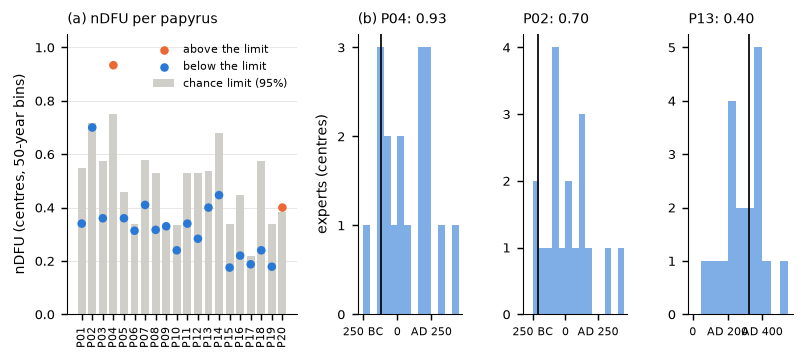

In [12]:
def year_label(v, _=None):
    v = int(round(v))
    return f"{-v} BC" if v < 0 else (f"AD {v}" if v > 0 else "0")

top = list(T.sort_values("nDFU", ascending=False).index[:2])
show_pap = top + [p for p in ["P13"] if p not in top]

fig = plt.figure(figsize=(DOUBLE, 2.8))
gs = fig.add_gridspec(1, 1 + len(show_pap), width_ratios=[2.2] + [1] * len(show_pap), wspace=0.45)
ax = fig.add_subplot(gs[0])
x = np.arange(nP)
ax.bar(x, T["chance 95%"], color=GREY_L, width=0.75, label="chance limit (95%)")
ax.scatter(x, T["nDFU"], c=list(np.where(T.polarised, ORANGE, BLUE)), s=14, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(pids, rotation=90, fontsize=6)
ax.set_ylim(0, 1.05); ax.set_ylabel("nDFU (centres, 50-year bins)")
ax.set_title("(a) nDFU per papyrus", loc="left")
ax.yaxis.grid(True, color=GRID_C, lw=0.5); ax.set_axisbelow(True)
ax.scatter([], [], c=ORANGE, s=14, label="above the limit")
ax.scatter([], [], c=BLUE, s=14, label="below the limit")
ax.legend(frameon=False, loc="upper right", fontsize=6)

e = edges(50)
for k, pid in enumerate(show_pap):
    p = pids.index(pid)
    ax = fig.add_subplot(gs[k + 1])
    counts, _ = np.histogram(C[p], bins=e)
    ax.bar(e[:-1], counts, width=50, align="edge", color=BLUE, alpha=0.6, lw=0)
    ax.axvline(y[p], color=INK, lw=1)
    ax.set_xlim(min(C[p].min(), y[p]) - 75, max(C[p].max(), y[p]) + 75)
    ax.xaxis.set_major_formatter(year_label); ax.locator_params(axis="x", nbins=3)
    ax.tick_params(axis="x", labelsize=6)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_title(f"{'(b) ' if k == 0 else ''}{pid}: {T.loc[pid, 'nDFU']:.2f}", loc="left")
    if k == 0:
        ax.set_ylabel("experts (centres)")
fig.savefig("figures/fig6_ndfu.pdf", bbox_inches="tight"); plt.show()

## Notes
- nDFU looks at rises between **neighbouring** bins, so it depends on the bin width: on one-year bins it is close to 0, on bins too narrow for 18 answers almost every papyrus looks polarised. The 50-year bins follow the design of the study (one papyrus per half-century) and should be reported with the chance limit.
- One expert far from the others can create a group on their own (one answer = 1/18 of the histogram). Check the groups column before reading a high nDFU as a split between experts.
- Pooling the ranges smooths the histogram, because the ranges are wide (134 years on average) and overlap; the pooled nDFU is lower than that of the centres.
- With 20 papyri and 18 experts, the polarised cases are illustrations, not a result about palaeographic dating in general.

**Reference.** J. Pavlopoulos and A. Likas. *Polarized Opinion Detection Improves the Detection of Toxic Language.* EACL 2024. https://aclanthology.org/2024.eacl-long.117/